In [1]:
import hashlib
from pathlib import Path
import pyarrow.parquet as pq

CACHE_OUT_DIR = Path("nyiso_data/merged_parquet")

def compute_fast_disk_fingerprint(
    data_dir: Path = CACHE_OUT_DIR,
    **params,
) -> str:
    """Computes a deterministic SHA-256 fingerprint from Parquet file metadata without loading data."""
    hasher = hashlib.sha256()
    
    # Inspect the underlying parquet files directly via PyArrow metadata (O(1) read)
    target_files = [
        "nodal_dart_spread.parquet",
        "zonal_dart_spread.parquet",
        "exogenous_features.parquet",
    ]
    for fname in target_files:
        fpath = data_dir / fname
        if not fpath.exists():
            # Force cache miss if underlying parquet files haven't been built yet
            hasher.update(f"{fname}:MISSING".encode("utf-8"))
            continue
        
        meta = pq.read_metadata(fpath)
        stat = fpath.stat()
        sig = (
            f"{fname}:rows={meta.num_rows}:cols={meta.num_columns}:"
            f"schema={meta.schema.names[:5]}-{meta.schema.names[-5:]}:"
            f"size={stat.st_size}:mtime={stat.st_mtime_ns}"
        )
        hasher.update(sig.encode("utf-8"))

    for k, v in sorted(params.items()):
        hasher.update(f"{k}={v}".encode("utf-8"))
        
    return hasher.hexdigest()


In [2]:
from typing import Callable, Optional
import numpy as np
import pandas as pd

from data_loader import load_data
from baseline2 import evaluate_baselines
from dmd import evaluate_dmd_baselines

def run_or_load_all_baselines(
    data_loader_fn: Callable[[], dict] = load_data,
    data: Optional[dict] = None,
    target_zone: str = "N.Y.C.",
    val_end: str = "2023-12-31 23:00:00",
    train_end: str = "2024-12-31 23:00:00",
    fee_per_mwh: float = 0.50,
    force_recompute: bool = False,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, Optional[dict]]:
    """
    Loads cached baseline results instantly without calling load_data().
    Only invokes data_loader_fn() if cache is missing, stale, or force_recompute=True.
    """
    CACHE_OUT_DIR.mkdir(parents=True, exist_ok=True)
    zone_slug = target_zone.replace(".", "").replace(" ", "_")
    res_path = CACHE_OUT_DIR / f"stage1_baseline_results_{zone_slug}.parquet"
    pnl_path = CACHE_OUT_DIR / f"stage1_baseline_unit_pnl_{zone_slug}.parquet"
    sig_path = CACHE_OUT_DIR / f"stage1_signals_{zone_slug}.parquet"
    hash_path = CACHE_OUT_DIR / f"stage1_baselines_{zone_slug}.hash"

    fp = compute_fast_disk_fingerprint(
        data_dir=CACHE_OUT_DIR,
        target_zone=target_zone,
        val_end=val_end,
        train_end=train_end,
        fee_per_mwh=fee_per_mwh,
        version="v1",
    )

    if (
        not force_recompute
        and res_path.exists()
        and pnl_path.exists()
        and sig_path.exists()
        and hash_path.exists()
        and hash_path.read_text().strip() == fp
    ):
        print(f"[CACHE HIT] Loaded all 14 baselines for {target_zone} (<0.1s) — skipped load_data()")
        return (
            pd.read_parquet(res_path),
            pd.read_parquet(pnl_path),
            pd.read_parquet(sig_path),
            data,  # None unless already loaded
        )

    # Cache miss: now load the full dataset
    if data is None:
        print("[CACHE MISS] Loading full NYISO dataset via load_data()...")
        data = data_loader_fn()
        # Recompute fingerprint in case load_data() updated the underlying parquet files
        fp = compute_fast_disk_fingerprint(
            data_dir=CACHE_OUT_DIR,
            target_zone=target_zone,
            val_end=val_end,
            train_end=train_end,
            fee_per_mwh=fee_per_mwh,
            version="v1",
        )

    print(f"[COMPUTING] Running all 14 baselines for {target_zone}...")
    baseline_results, baseline_pnl, baseline_signals = evaluate_baselines(
        data=data,
        target_zone=target_zone,
        val_end=val_end,
        train_end=train_end,
        fee_per_mwh=fee_per_mwh,
    )

    dmd_results, dmd_pnl = evaluate_dmd_baselines(
        data=data,
        target_zone=target_zone,
        train_end=train_end,
        fee_per_mwh=fee_per_mwh,
    )

    spread_te = data["zonal_dart"][target_zone].reindex(dmd_pnl.index)
    dmd_signals = pd.DataFrame(index=dmd_pnl.index)
    for col in dmd_pnl.columns:
        pnl_vals = dmd_pnl[col].to_numpy()
        s_vals = spread_te.to_numpy()
        sig = np.zeros(len(pnl_vals), dtype=int)
        active = pnl_vals != 0.0
        sig[active] = np.sign(
            (pnl_vals[active] + fee_per_mwh) / np.where(s_vals[active] == 0, 1e-6, s_vals[active])
        ).astype(int)
        dmd_signals[col] = sig

    all_baselines_df = (
        pd.concat([baseline_results, dmd_results], ignore_index=True)
        .sort_values(by="Annual Sharpe", ascending=False)
        .reset_index(drop=True)
    )
    all_baseline_pnl = pd.concat([baseline_pnl, dmd_pnl], axis=1)
    all_baseline_signals = pd.concat([baseline_signals, dmd_signals], axis=1)

    all_baselines_df.to_parquet(res_path)
    all_baseline_pnl.to_parquet(pnl_path)
    all_baseline_signals.to_parquet(sig_path)
    hash_path.write_text(fp)
    print(f"[SAVED] Cached 14 baselines to {CACHE_OUT_DIR}/")

    return all_baselines_df, all_baseline_pnl, all_baseline_signals, data


In [3]:
# Optional helper if a later cell in your notebook actually needs `data`
def get_data():
    global data
    if data is None:
        data = load_data()
    return data

In [4]:
# Execute: computes once, then hits cache instantly on every subsequent notebook run
all_baselines_df, all_baseline_pnl, all_baseline_signals, data = run_or_load_all_baselines(
    target_zone="N.Y.C.",
)
display(all_baselines_df)

[CACHE MISS] Loading full NYISO dataset via load_data()...


P-54B (rt_actual_outages) [83/83 cached]: 100%|██████████| 83/83 [00:00<00:00, 831.61zip/s]
P-511A (dam_limiting_constraints) [249/249 cached]: 100%|██████████| 249/249 [00:00<00:00, 5060.87zip/s]
P-27 (dam_bid_data) [474/474 cached]: 100%|██████████| 474/474 [00:00<00:00, 2081.47zip/s]


[CACHE HIT] Loading dam_lbmp_gen.parquet...
[CACHE HIT] Loading rt_int_lbmp_gen.parquet...
[CACHE HIT] Loading dam_lbmp_zone.parquet...
[CACHE HIT] Loading rt_int_lbmp_zone.parquet...
[CACHE HIT] Loading iso_load_forecast.parquet...
[CACHE HIT] Loading weather_forecast.parquet...
[CACHE HIT] Loading zonal_bid_load.parquet...
[CACHE HIT] Loading btm_solar_forecast.parquet...
[CACHE HIT] Loading rt_int_actual_load.parquet...
[CACHE HIT] Loading dam_sched_outages.parquet...
[CACHE HIT] Loading rt_actual_outages.parquet...
[CACHE HIT] Loading dam_limiting_constraints.parquet...
[CACHE HIT] Loading rt_fuel_mix.parquet...
[CACHE HIT] Loading interface_flows.parquet...
[CACHE HIT] Partitioned dataset ready at nyiso_data/merged_parquet/dam_bid_data/...
[CACHE HIT] Loading nodal_dart_spread.parquet & labels...
[CACHE HIT] Loading zonal_dart_spread.parquet & labels...
[CACHE HIT] Loading exogenous_features.parquet...

=== Pipeline Complete ===
Nodal DART Matrix:      (59958, 559) (Timestamps x G

,Model,Feature Set,Macro F1,Tail F1,Trades,Trade Freq (%),Win Rate (%),Avg PnL/Trade ($),Cum PnL ($),Annual Sharpe,Max DD ($)
0,Continuous Ridge Regression,Exog + 559 Nodes,0.3798,0.2384,6914,42.4,47.8,4.04,27963.84,3.50,4969.93
1,Natural-Prior MLP (tau-tuned) [tau=0.24],Exog-Only,0.3899,0.2571,7601,46.6,53.9,3.64,27698.79,2.82,11120.52
2,Causal 48h Persistence,Target Lags,0.4163,0.2547,5217,32.0,50.6,4.29,22388.24,2.31,6488.46
3,Galarneau-Vincent et al. (2023) GBDT,Exog + 559 Nodes,0.4502,0.3142,6812,41.8,58.1,3.48,23709.37,2.17,19928.86
4,Hubert et al. (2026) Multinomial Logit,Exog + 559 Nodes,0.3680,0.3041,11200,68.7,54.1,1.74,19539.42,1.78,18823.72
5,Hubert et al. (2026) Logit (tau-tuned) [tau=0.18],Exog-Only,0.3805,0.3105,10943,67.1,53.6,1.74,19061.51,1.73,14894.24
6,Hubert et al. (2026) Multinomial Logit,Exog-Only,0.3693,0.3060,11273,69.1,53.5,1.55,17509.44,1.59,16320.78
7,Hourly ARIMAX (24-hr),"Exog + AR(48,72,168)",0.3499,0.1238,1594,9.8,39.6,5.87,9355.99,1.25,11031.63
8,Galarneau-Vincent et al. (2023) GBDT,Exog-Only,0.4485,0.3053,6441,39.5,57.7,2.11,13602.31,1.24,26114.26
9,Reference LDA,Exog-Only,0.4060,0.2233,3943,24.2,55.8,2.56,10099.97,0.95,19076.51


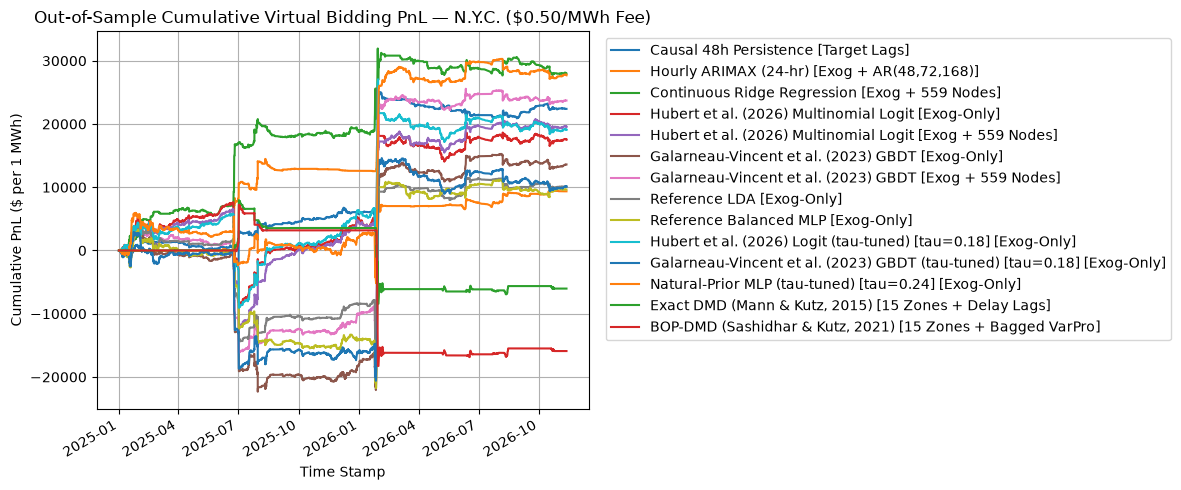

In [5]:
import matplotlib.pyplot as plt

# 4. Plot cumulative out-of-sample PnL curves (2025–2026)
ax = all_baseline_pnl.cumsum().plot(
    figsize=(12, 5),
    title="Out-of-Sample Cumulative Virtual Bidding PnL — N.Y.C. ($0.50/MWh Fee)",
    ylabel="Cumulative PnL ($ per 1 MWh)",
    grid=True,
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [6]:
import numpy as np
import pandas as pd

def run_tail_attribution(
    pnl_df: pd.DataFrame,
    signals_df: pd.DataFrame,
    zonal_dart: pd.Series,
    top_k_list: tuple[int, ...] = (5, 10, 25, 50),
) -> pd.DataFrame:
    """Decomposes model PnL into core edge vs. extreme tail hours and regime windows."""
    dart_aligned = zonal_dart.reindex(pnl_df.index)
    
    # Define the two visual jump windows
    summer_2025 = (pnl_df.index >= "2025-06-15") & (pnl_df.index <= "2025-07-31")
    winter_2026 = (pnl_df.index >= "2026-01-15") & (pnl_df.index <= "2026-02-28")
    other_hours = ~(summer_2025 | winter_2026)

    # Identify top 1% most extreme absolute DART spread hours
    q99 = dart_aligned.abs().quantile(0.99)
    non_tail_mask = dart_aligned.abs() <= q99

    rows = []
    for model in pnl_df.columns:
        p = pnl_df[model]
        total_pnl = p.sum()
        
        # Annualized Sharpe (hourly -> sqrt(8760))
        full_sharpe = (p.mean() / (p.std() + 1e-9)) * np.sqrt(8760)
        
        # Trimmed Sharpe (excluding top 1% most extreme DART spread hours)
        p_core = p[non_tail_mask]
        core_sharpe = (p_core.mean() / (p_core.std() + 1e-9)) * np.sqrt(8760)
        
        # PnL contribution of the model's top-K single best hours
        sorted_p = p.sort_values(ascending=False)
        top_k_shares = {
            f"Top {k} Hrs ($)": round(sorted_p.iloc[:k].sum(), 2)
            for k in top_k_list
        }

        rows.append({
            "Model": model,
            "Total PnL ($)": round(total_pnl, 2),
            "Summer 25 Jump ($)": round(p[summer_2025].sum(), 2),
            "Winter 26 Jump ($)": round(p[winter_2026].sum(), 2),
            "Rest of Period ($)": round(p[other_hours].sum(), 2),
            "Full Sharpe": round(full_sharpe, 2),
            "Core Sharpe (ex-1% Tail)": round(core_sharpe, 2),
            **top_k_shares,
        })

    return pd.DataFrame(rows).sort_values("Full Sharpe", ascending=False).reset_index(drop=True)

# Run attribution check
data = get_data()  # uses your lazy loader
attr_df = run_tail_attribution(
    pnl_df=all_baseline_pnl,
    signals_df=all_baseline_signals,
    zonal_dart=data["zonal_dart"]["N.Y.C."],
)
display(attr_df)


,Model,Total PnL ($),Summer 25 Jump ($),Winter 26 Jump ($),Rest of Period ($),Full Sharpe,Core Sharpe (ex-1% Tail),Top 5 Hrs ($),Top 10 Hrs ($),Top 25 Hrs ($),Top 50 Hrs ($)
0,Continuous Ridge Regression [Exog + 559 Nodes],27963.84,13250.08,12285.97,2427.79,3.50,1.20,7931.52,11781.95,19989.86,29355.85
1,Natural-Prior MLP (tau-tuned) [tau=0.24] [Exog...,27698.79,-2946.64,25982.85,4662.58,2.82,3.53,4838.78,8429.71,17007.99,26860.26
2,Causal 48h Persistence [Target Lags],22388.24,3604.95,17764.99,1018.30,2.31,0.53,8934.96,12642.13,21673.08,31416.95
3,Galarneau-Vincent et al. (2023) GBDT [Exog + 5...,23709.37,-15844.07,33702.67,5850.77,2.17,5.52,4713.80,8265.06,16275.86,25634.21
4,Hubert et al. (2026) Multinomial Logit [Exog +...,19539.42,-11068.22,14586.58,16021.06,1.78,4.91,6809.27,10446.49,19097.76,28825.78
5,Hubert et al. (2026) Logit (tau-tuned) [tau=0....,19061.51,-7795.15,15763.50,11093.16,1.73,4.24,6804.80,10395.73,19140.57,28880.81
6,Hubert et al. (2026) Multinomial Logit [Exog-O...,17509.44,-9212.85,13649.35,13072.94,1.59,4.25,6804.80,10395.73,19040.45,28730.38
7,"Hourly ARIMAX (24-hr) [Exog + AR(48,72,168)]",9355.99,13962.96,-5569.22,962.25,1.25,-2.58,9429.94,12694.26,18815.79,24564.92
8,Galarneau-Vincent et al. (2023) GBDT [Exog-Only],13602.31,-20710.06,30526.90,3785.47,1.24,4.73,3818.00,7213.30,14788.96,24006.00
9,Reference LDA [Exog-Only],10099.97,-14406.33,19030.93,5475.37,0.95,3.39,4713.80,8265.06,16502.78,25972.76
